# **DATA PREPARATION**

In [1]:
# Necessary Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

c:\Users\linhk\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# 1. QUAN TRỌNG NHẤT: Ngăn Pandas tự động ngắt và xuống dòng khi bảng quá rộng
pd.set_option('display.expand_frame_repr', False)

# 2. Hiển thị toàn bộ các cột (không bị ẩn bớt thành dấu ba chấm "...")
pd.set_option('display.max_columns', None)

# 3. Tăng giới hạn độ rộng hiển thị (ví dụ đặt là 1000 ký tự trên một dòng)
pd.set_option('display.width', 1000)

# 4. Hiển thị đầy đủ chữ trong mỗi ô dữ liệu (không bị cắt ngắn chữ)
pd.set_option('display.max_colwidth', None)

In [3]:
# Raw Data Loading
r_nvidia_data = pd.read_csv("NVIDIA_STOCK.csv")
print(r_nvidia_data.head())

        Price           Adj Close               Close               High                Low               Open     Volume
0      Ticker                NVDA                NVDA               NVDA               NVDA               NVDA       NVDA
1        Date                 NaN                 NaN                NaN                NaN                NaN        NaN
2  2018-01-02   4.929879665374756   4.983749866485596  4.987500190734863  4.862500190734863  4.894499778747559  355616000
3  2018-01-03   5.254334926605225  5.3117499351501465   5.34250020980835            5.09375  5.102499961853027  914704000
4  2018-01-04  5.2820329666137695   5.339749813079834  5.451250076293945  5.317249774932861  5.394000053405762  583268000


In [ ]:
# Adjusting column names
r_nvidia_data.drop(index=r_nvidia_data.index[0:2], inplace=True)
r_nvidia_data.rename(columns={'Price': 'Date'}, inplace=True)
print(r_nvidia_data.head())

         Date           Adj Close               Close               High                 Low               Open     Volume
2  2018-01-02   4.929879665374756   4.983749866485596  4.987500190734863   4.862500190734863  4.894499778747559  355616000
3  2018-01-03   5.254334926605225  5.3117499351501465   5.34250020980835             5.09375  5.102499961853027  914704000
4  2018-01-04  5.2820329666137695   5.339749813079834  5.451250076293945   5.317249774932861  5.394000053405762  583268000
5  2018-01-05   5.326793670654297   5.385000228881836  5.422749996185303  5.2769999504089355  5.354750156402588  580124000
6  2018-01-08   5.490012168884277   5.550000190734863              5.625  5.4644999504089355  5.510000228881836  881216000


In [5]:
# Checking for missing data and duplicates
initial_rows = len(r_nvidia_data)

nvidia_data = r_nvidia_data.dropna().drop_duplicates()

na_dropped = len(r_nvidia_data) - len(r_nvidia_data.dropna())
dup_dropped = len(r_nvidia_data.dropna()) - len(nvidia_data)

print("From the initial dataset of {} rows:  \n- {} rows were dropped due to missing values, \n- {} rows were dropped due to duplicates. \nThe final dataset contains {} rows.".format(initial_rows, na_dropped, dup_dropped, len(nvidia_data)))

print(nvidia_data.describe())

From the initial dataset of 1697 rows:  
- 0 rows were dropped due to missing values, 
- 0 rows were dropped due to duplicates. 
The final dataset contains 1697 rows.
              Date         Adj Close              Close  High                Low               Open     Volume
count         1697              1697               1697  1697               1697               1697       1697
unique        1697              1685               1674  1662               1672               1662       1695
top     2018-01-02  6.12962007522583  6.192749977111816  6.25  6.168749809265137  5.949999809265137  295420000
freq             1                 2                  2     3                  3                  3          2


In [6]:
nvidia_data['Date'] = pd.to_datetime(nvidia_data['Date'])

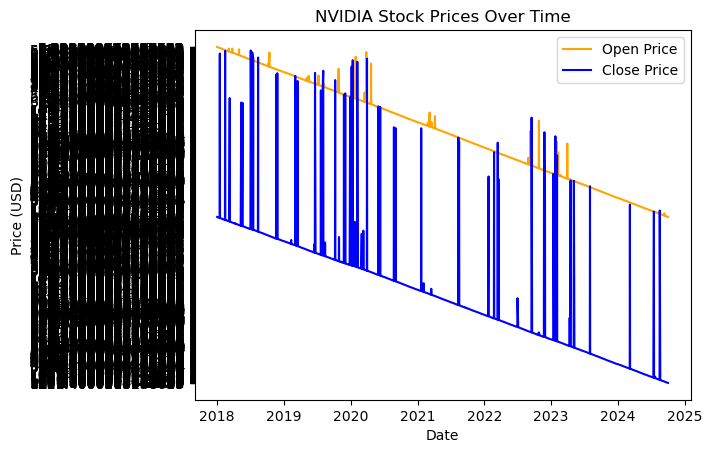

In [8]:
# 1. Clean and convert the Date column first
nvidia_data['Date'] = pd.to_datetime(nvidia_data['Date'], errors='coerce')
nvidia_data = nvidia_data.dropna(subset=['Date'])

# 2. Reset index if needed (use drop=True to avoid naming collisions)
nvidia_data = nvidia_data.reset_index(drop=True)

# 3. Then run your Seaborn plots right after
sns.lineplot(data=nvidia_data, x='Date', y='Open', label='Open Price', color='orange')
sns.lineplot(data=nvidia_data, x='Date', y='Close', label='Close Price', color='blue')

plt.title('NVIDIA Stock Prices Over Time')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [16]:
# test ideas
# 1. Identify days with volume spikes: Divide each day’s volume by the average volume of the prior 20 sessions
nvidia_test = nvidia_data.copy()
nvidia_test['Volume_Spike'] = nvidia_test['Volume'] / nvidia_test['Volume'].shift(1).rolling(window=20).mean()
print(nvidia_test[['Date', 'Volume', 'Volume_Spike']].head(30))

         Date        Volume  Volume_Spike
0  2018-01-02  3.556160e+08           NaN
1  2018-01-03  9.147040e+08           NaN
2  2018-01-04  5.832680e+08           NaN
3  2018-01-05  5.801240e+08           NaN
4  2018-01-08  8.812160e+08           NaN
5  2018-01-09  4.970000e+08           NaN
6  2018-01-10  5.826640e+08           NaN
7  2018-01-11  4.060320e+08           NaN
8  2018-01-12  3.599160e+08           NaN
9  2018-01-16  7.023480e+08           NaN
10 2018-01-17  5.384080e+08           NaN
11 2018-01-18  4.086320e+08           NaN
12 2018-01-19  6.093800e+08           NaN
13 2018-01-22  5.509440e+08           NaN
14 2018-01-23  4.752280e+08           NaN
15 2018-01-24  5.799720e+08           NaN
16 2018-01-25  4.098840e+08           NaN
17 2018-01-26  5.163560e+08           NaN
18 2018-01-29  4.551160e+08           NaN
19 2018-01-30  5.708320e+08           NaN
20 2018-01-31  4.785760e+08      0.871911
21 2018-02-01  5.192240e+08      0.935488
22 2018-02-02  7.184640e+08      1

In [ ]:
# Flag large moves on high volume days: Identify days where the stock price moved more than 2% and the volume was in the top 10% of all days.
nvidia_test['Daily_Return'] = nvidia_test['Adj Close'].pct_change()
nvidia_test['Large_Move'] = (abs(nvidia_test['Daily_Return']) > 0.02) & (nvidia_test['Volume'] > 1.5)

# Calculate what happened five sessions later: Did the stock price continue, go in the reversed direction, or stay flat?
# It continued if the number of the next 5 sessions was also positive/negative, went in the reverse direction if the contrary happened, 
# and stayed flat if that went to 0%. 
# Create a new column to store this information.
nvidia_test['Next_5_Sessions_Return'] = nvidia_test['Adj Close'].shift(-5) / nvidia_test['Adj Close'] - 1
nvidia_test['Label'] = nvidia_test['Next_5_Sessions_Return'].apply(lambda x: 'Continued' if x*x.shift(-5) > 0 else ('Reversed' if x*x.shift(-5) < 0 else 'Flat'))

TypeError: operation 'truediv' not supported for dtype 'str' with dtype 'str'